In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

# Loading the dataset, specifying the full path within your Drive
df = pd.read_csv("/content/hindi_sms_dataset_extended.csv")
# Display the first few rows to understand the structure
df.head()



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,labels,text
0,ham,मुझे तुम्हारा ईमेल मिला।
1,ham,तुम आज ऑफिस आ रहे हो?
2,ham,डॉक्टर की अपॉइंटमेंट कब है?
3,ham,तुम्हारा दिन कैसा रहा?
4,spam,आप जीत गए हैं अभी कार्रवाई करें!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   labels  5000 non-null   object
 1   text    5000 non-null   object
dtypes: object(2)
memory usage: 78.3+ KB
None
       labels                   text
count    5000                   5000
unique      2                     44
top       ham  तुम आज ऑफिस आ रहे हो?
freq     2575                    143


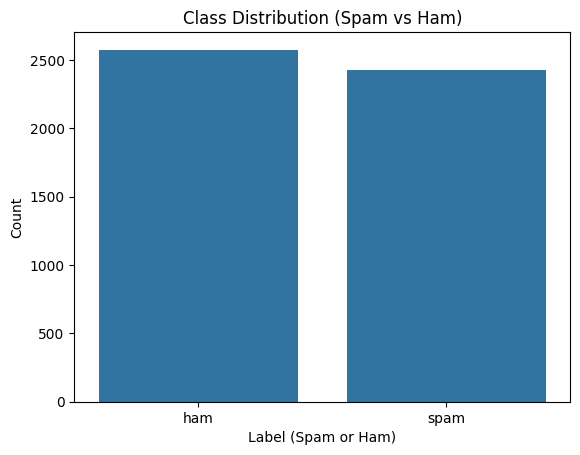

labels    0
text      0
dtype: int64

Missing values in 'labels' and 'text':
Labels missing: 0
Text missing: 0


In [ ]:
# Perform EDA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Display dataset info and summary statistics
print(df.info())  # Information about dataset
print(df.describe())  # Summary statistics

# Visualize the class distribution (if it's a classification task)
sns.countplot(x='labels', data=df)  # Use 'labels' as the column for class distribution
plt.title("Class Distribution (Spam vs Ham)")
plt.xlabel("Label (Spam or Ham)")  # Label for x-axis
plt.ylabel("Count")  # Label for y-axis
plt.show()

# Check for missing values in the dataset
print(df.isnull().sum())  # Check for missing values in all columns

# Check for missing values specifically in 'labels' and 'text' columns
print("\nMissing values in 'labels' and 'text':")
print("Labels missing:", df['labels'].isnull().sum())
print("Text missing:", df['text'].isnull().sum())


In [ ]:
!pip install fasttext


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-2.13.6-py3-none-any.whl.metadata (9.5 kB)
Using cached pybind11-2.13.6-py3-none-any.whl (243 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp311-cp311-linux_x86_64.whl size=4313508 sha256=03c2a0aaaa926453607f6dff17f0266cdbf0b54746c0791db83a3831821bf094
  Stored in directory: /root/.cache/pip/wheels/65/4f/35/5057db0249224e9ab55a513fa6b79451473ceb7713017823c3
Successfully built fasttext


In [ ]:
#Text Processing (Cleaning the data)
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.bin.gz
!gunzip cc.en.300.bin.gz  # This decompresses the file after download
import joblib
import re
import fasttext
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Download NLTK stopwords


# Load dataset
df = pd.read_csv("/content/drive/MyDrive/mini projects/NLP/.hindi_sms_dataset_extended.csv")
df.dropna(inplace=True)

# Load Hindi stopwords
def load_hindi_stopwords(filepath):
    with open(filepath, 'r', encoding='utf-8') as file:
        hindi_stopwords = [word.strip() for word in file.read().splitlines()]
    return set(hindi_stopwords)

stop_words = load_hindi_stopwords('/content/drive/MyDrive/mini projects/NLP/hindi_stopwords.txt')

# Text cleaning function
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s\u0900-\u097F]', ' ', str(text))  # Allow Hindi characters
    text = text.lower()
    text = ' '.join([word.strip() for word in text.split() if word.strip() not in stop_words])
    return text

df['cleaned_text'] = df['text'].apply(clean_text)

# Feature extraction
def generate_nlp_features(df):
    df['char_count'] = df['cleaned_text'].apply(len)
    df['word_count'] = df['cleaned_text'].apply(lambda x: len(x.split()))
    df['avg_word_length'] = df['cleaned_text'].apply(lambda x: np.mean([len(word) for word in x.split()]) if x.split() else 0)
    df['stopword_count'] = df['cleaned_text'].apply(lambda x: len([word for word in x.split() if word in stop_words]))
    df['htag_count'] = df['cleaned_text'].apply(lambda x: x.count('#'))
    return df

df = generate_nlp_features(df)

# Load FastText model
ft_model = fasttext.load_model('cc.en.300.bin')

# Function to get FastText embeddings
def get_fasttext_embeddings(text):
    words = text.split()
    if not words:  # Handle empty text
        return np.zeros(300)
    word_vectors = [ft_model.get_word_vector(word) for word in words]
    return np.mean(word_vectors, axis=0)

df['fasttext_embeddings'] = df['cleaned_text'].apply(get_fasttext_embeddings)

# Convert FastText embeddings to numpy array
X_ft = np.vstack(df['fasttext_embeddings'].values)

# Text Vectorization
bow_vectorizer = CountVectorizer(max_features=5000)
X_bow = bow_vectorizer.fit_transform(df['cleaned_text'])

# Save BoW vectorizer
joblib.dump(bow_vectorizer, '/content/drive/MyDrive/bow_vectorizer.pkl')

tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_text'])

# Save TFIDF vectorizer
joblib.dump(tfidf_vectorizer, '/content/drive/MyDrive/tfidf_vectorizer.pkl')


# Define input features & target variable
X = df[['char_count', 'word_count', 'avg_word_length', 'stopword_count', 'htag_count']]
y = df['labels']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train SVM Model
svm_model = SVC(kernel='linear', C=0.5, class_weight='balanced')
svm_model.fit(X_train, y_train)
joblib.dump(svm_model, '/content/drive/MyDrive/svm_model.pkl')

# Model Evaluation
y_pred = svm_model.predict(X_test)

# Print accuracy and classification report
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))


--2025-06-17 15:42:21--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.bin.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.226.210.25, 13.226.210.15, 13.226.210.111, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.226.210.25|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4503593528 (4.2G) [application/octet-stream]
Saving to: ‘cc.en.300.bin.gz’

cc.en.300.bin.gz    100%[===================>]   4.19G  67.6MB/s    in 39s     

2025-06-17 15:43:00 (109 MB/s) - ‘cc.en.300.bin.gz’ saved [4503593528/4503593528]

gzip: cc.en.300.bin already exists; do you wish to overwrite (y or n)? n
	not overwritten
SVM Accuracy: 0.8540
              precision    recall  f1-score   support

         ham       0.96      0.74      0.84       511
        spam       0.78      0.97      0.87       489

    accuracy                           0.85      1000
   macro avg       0.87      0.86      0.85      1000
weighted avg       0

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import numpy as np

# Train models on Bag of Words (BoW)
X_train, X_test, y_train, y_test = train_test_split(X_bow, y, test_size=0.2, random_state=42)
svm_model_bow = SVC(kernel='linear')
svm_model_bow.fit(X_train, y_train)
y_pred_bow = svm_model_bow.predict(X_test)
print(f'BoW Accuracy: {accuracy_score(y_test, y_pred_bow)}')

# Train models on TFIDF features
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)
svm_model_tfidf = SVC(kernel='linear')
svm_model_tfidf.fit(X_train, y_train)
y_pred_tfidf = svm_model_tfidf.predict(X_test)
print(f'TFIDF Accuracy: {accuracy_score(y_test, y_pred_tfidf)}')

# Train models on FastText embeddings
X_train, X_test, y_train, y_test = train_test_split(np.vstack(df['fasttext_embeddings']), y, test_size=0.2, random_state=42)
svm_model_fasttext = SVC(kernel='linear')
svm_model_fasttext.fit(X_train, y_train)
y_pred_fasttext = svm_model_fasttext.predict(X_test)

print(f'FastText Accuracy: {accuracy_score(y_test, y_pred_fasttext)}')

BoW Accuracy: 1.0
TFIDF Accuracy: 1.0
FastText Accuracy: 1.0


In [ ]:
from scipy.sparse import hstack

# Combine NLP features and TFIDF features
X_combined = hstack([X.values, X_tfidf])  # Convert X to a NumPy array

# Train model and evaluate
X_train, X_test, y_train, y_test = train_test_split(X_combined, y, test_size=0.2, random_state=42)

svm_model_combined = SVC(kernel='linear')
svm_model_combined.fit(X_train, y_train)
y_pred_combined = svm_model_combined.predict(X_test)

print(f'Combined Features Accuracy: {accuracy_score(y_test, y_pred_combined)}')











Combined Features Accuracy: 1.0


In [ ]:
import joblib
from scipy.sparse import hstack

# Save the trained models
joblib.dump(svm_model_bow, '/content/drive/MyDrive/svm_model_bow.pkl')
joblib.dump(svm_model_tfidf, '/content/drive/MyDrive/svm_model_tfidf.pkl')
joblib.dump(svm_model_fasttext, '/content/drive/MyDrive/svm_model_fasttext.pkl')
joblib.dump(svm_model_combined, '/content/drive/MyDrive/svm_model_combined.pkl')

['/content/drive/MyDrive/svm_model_combined.pkl']

In [ ]:
# Load models for predictions
loaded_model_bow = joblib.load('/content/drive/MyDrive/svm_model_bow.pkl')
loaded_model_tfidf = joblib.load('/content/drive/MyDrive/svm_model_tfidf.pkl')
loaded_model_fasttext = joblib.load('/content/drive/MyDrive/svm_model_fasttext.pkl')
loaded_model_combined = joblib.load('/content/drive/MyDrive/svm_model_combined.pkl')

# Take user input for prediction
new_text = [input("Enter text for classification: ")]
new_text_cleaned = [clean_text(text) for text in new_text]

# Extract features for each method
new_text_bow = bow_vectorizer.transform(new_text_cleaned)
new_text_tfidf = tfidf_vectorizer.transform(new_text_cleaned)
new_text_fasttext = np.array([get_fasttext_embeddings(text) for text in new_text_cleaned])
new_text_combined = hstack([np.array([[len(text), len(text.split()), np.mean([len(word) for word in text.split()]) if text.split() else 0, len([word for word in text.split() if word in stop_words]), text.count('#')] for text in new_text_cleaned]), new_text_tfidf])

# Predict using trained models
prediction_bow = loaded_model_bow.predict(new_text_bow)
prediction_tfidf = loaded_model_tfidf.predict(new_text_tfidf)
prediction_fasttext = loaded_model_fasttext.predict(new_text_fasttext)
prediction_combined = loaded_model_combined.predict(new_text_combined)

print(f'SVM Prediction using BoW: {prediction_bow}')
print(f'SVM Prediction using TFIDF: {prediction_tfidf}')
print(f'SVM Prediction using FastText: {prediction_fasttext}')
print(f'SVM Prediction using Combined Features: {prediction_combined}')


Enter text for classification: "बैंक" और "विशेष ऑफर" विश्वसनीय लगते हैं, लेकिन यह स्पैम या प्रचार हो सकता है।
SVM Prediction using BoW: ['ham']
SVM Prediction using TFIDF: ['ham']
SVM Prediction using FastText: ['ham']
SVM Prediction using Combined Features: ['spam']
